# 03 — Experimental Analysis

## Genetic Variant Classification Using ClinVar

This notebook investigates model interpretability, feature-group contributions, and generalization to previously unseen gene groups.

The analysis extends the model evaluation presented in `02_model_evaluation.ipynb`.

### Objectives

1. Examine Logistic Regression coefficients.
2. Analyze Random Forest feature importance.
3. Compare different feature configurations through an ablation study.
4. Evaluate model performance using gene-based train-test splits.
5. Investigate the variability of results across repeated experiments.
6. Discuss methodological limitations.

The analysis uses previously generated results from the project's evaluation pipeline.

No model training or preprocessing is performed in this notebook.

## 1. Environment Setup

The notebook uses Pandas and NumPy for numerical analysis, Matplotlib for visualization, and Pillow for displaying existing figures.

Experimental results are loaded from the project's `results/metrics/` directory.

Model interpretation figures are loaded from `results/figures/`.

This approach ensures consistency between the notebook, the evaluation scripts, and the graphical application.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

# Locate the project root.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

ABLATION_FILE = METRICS_DIR / "ablation_study.csv"
GENE_SPLIT_FILE = METRICS_DIR / "gene_split_comparison.csv"
GENE_SUMMARY_FILE = METRICS_DIR / "gene_split_summary.csv"

# Configure plot appearance.
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

COLORS = {
    "primary": "#9067C6",
    "secondary": "#7E9FCA",
    "neutral": "#A6A3B5",
    "highlight": "#B39DDB"
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Metrics directory: {METRICS_DIR}")
print(f"Figures directory: {FIGURES_DIR}")

Project root: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification
Metrics directory: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification/results/metrics
Figures directory: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification/results/figures


## 2. Feature Importance

Feature importance analysis helps explain how trained models use the available input characteristics.

The project includes two different classification approaches:

- **Logistic Regression:** A linear model whose coefficients describe associations between encoded features and the predicted log-odds of the pathogenic class.
- **Random Forest:** An ensemble model that estimates feature importance from impurity reductions across decision trees.

These interpretation methods are not directly equivalent.

Logistic Regression coefficients indicate the direction and magnitude of associations, whereas Random Forest feature importance values are non-negative and summarize contributions to tree-based decisions.

Neither method establishes causal relationships between genetic characteristics and pathogenicity.

### 2.1 Logistic Regression Coefficients

Logistic Regression estimates a coefficient for each transformed input feature.

A positive coefficient increases the predicted log-odds of the pathogenic class, while a negative coefficient decreases them, holding other encoded features constant.

Coefficient magnitudes depend on feature encoding, scaling, and correlations between predictors.

The following figure presents the coefficients generated during model evaluation.

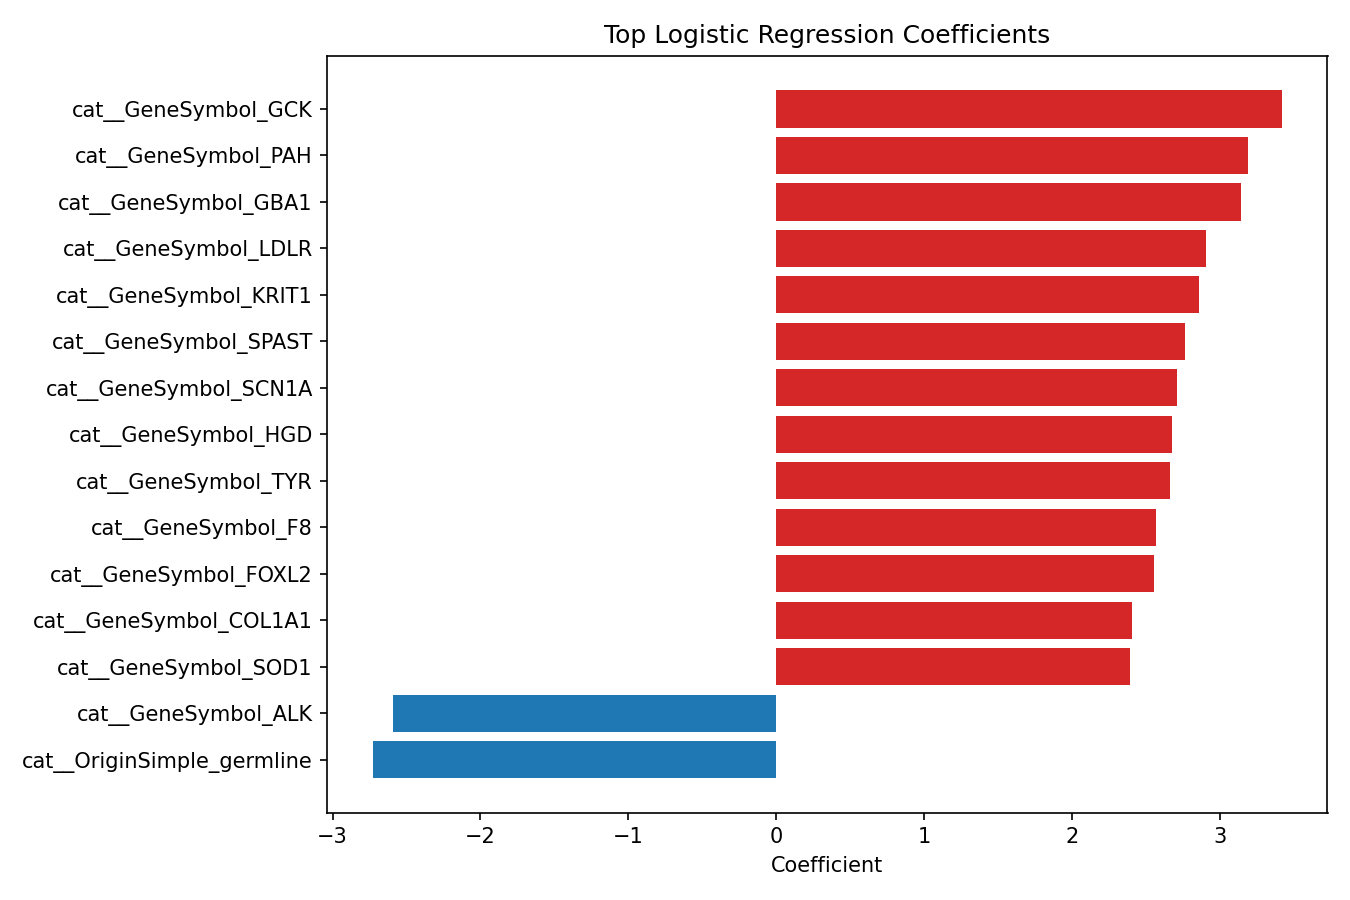

In [2]:
lr_figure = FIGURES_DIR / "logistic_regression_coefficients.png"

if lr_figure.exists():
    display(Image.open(lr_figure))
else:
    print(f"Figure not found: {lr_figure}")

### Interpretation

Logistic Regression coefficients reveal which encoded characteristics are associated with higher or lower predicted pathogenicity scores.

Positive coefficients contribute toward the pathogenic class, while negative coefficients contribute toward the benign class.

However, these associations should not be interpreted as biological causation.

The model uses a limited set of genomic and structural features, and its coefficients reflect statistical patterns in the selected ClinVar dataset.

Additionally, correlated features may influence coefficient magnitudes and complicate their interpretation.

### 2.2 Random Forest Feature Importance

Random Forest estimates feature importance by measuring the reduction in node impurity associated with each feature across the ensemble.

Features that contribute more strongly to splitting decisions generally receive higher importance values.

Unlike Logistic Regression coefficients, these importance values do not indicate whether a feature increases or decreases the predicted probability of pathogenicity.

Impurity-based importance may favor features with many possible split points or categories.

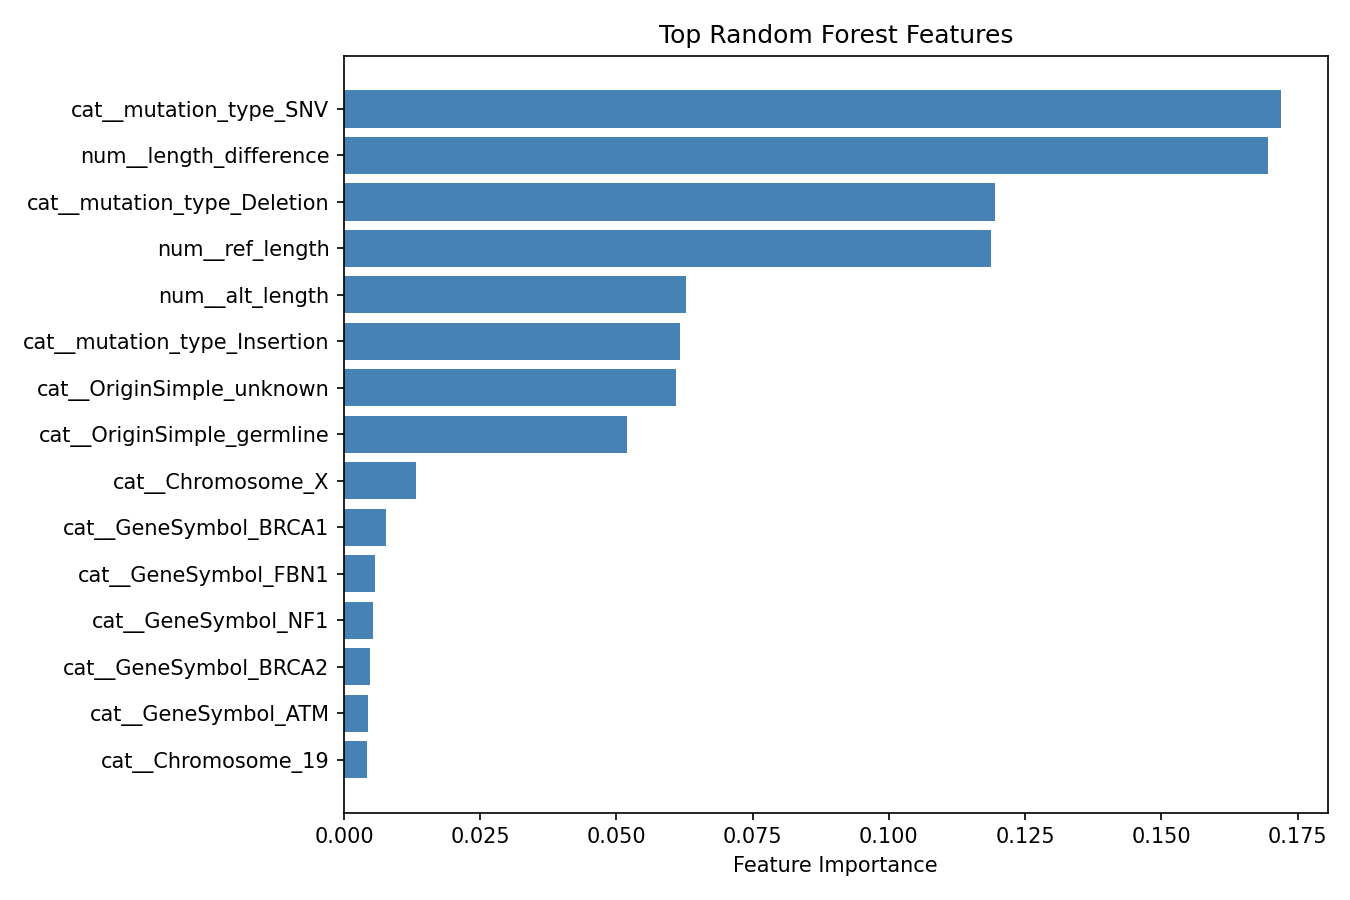

In [3]:
rf_figure = FIGURES_DIR / "random_forest_feature_importance.png"

if rf_figure.exists():
    display(Image.open(rf_figure))
else:
    print(f"Figure not found: {rf_figure}")

### Interpretation

Random Forest feature importance identifies the characteristics that contribute most strongly to the ensemble's splitting decisions.

These values describe how the trained model uses its input features.

A high importance score does not necessarily imply that a feature has a direct biological effect on pathogenicity.

Furthermore, correlated features may share importance, and impurity-based importance can be affected by feature cardinality.

The results should therefore be interpreted as model-specific explanations rather than biological conclusions.

## 3. Ablation Study

An ablation study evaluates the contribution of different feature groups by comparing model performance under alternative input configurations.

The project investigates four configurations:

1. **Structural Only:** Mutation type and allele-length characteristics.
2. **Structural + Genomic:** Structural features combined with genomic information.
3. **Structural + Origin:** Structural features combined with variant-origin metadata.
4. **Full Features:** All selected structural, genomic, and origin characteristics.

Logistic Regression is used to evaluate these configurations.

The purpose is to determine whether adding specific feature groups improves predictive performance.

In [4]:
# Load ablation study results.
ablation = pd.read_csv(ABLATION_FILE)

FEATURE_SET_NAMES = {
    "structural_only": "Structural Only",
    "structural_plus_genomic": "Structural + Genomic",
    "structural_plus_origin": "Structural + Origin",
    "full_features": "Full Features"
}

ablation["Feature Set"] = (
    ablation["feature_set"]
    .map(FEATURE_SET_NAMES)
)

ablation

,feature_set,accuracy,precision_pathogenic,recall_pathogenic,f1_pathogenic,roc_auc,pr_auc,Feature Set
0,structural_only,0.7069,0.897121,0.4674,0.614596,0.707311,0.690172,Structural Only
1,structural_plus_genomic,0.7535,0.800071,0.6759,0.732762,0.833329,0.846475,Structural + Genomic
2,structural_plus_origin,0.7246,0.897804,0.5069,0.647961,0.726484,0.715369,Structural + Origin
3,full_features,0.7641,0.817275,0.6803,0.742523,0.843109,0.857810,Full Features


In [5]:
ablation_display = ablation[
    [
        "Feature Set",
        "accuracy",
        "precision_pathogenic",
        "recall_pathogenic",
        "f1_pathogenic",
        "roc_auc",
        "pr_auc"
    ]
].rename(columns={
    "accuracy": "Accuracy",
    "precision_pathogenic": "Precision",
    "recall_pathogenic": "Recall",
    "f1_pathogenic": "F1-score",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC"
})

display(
    ablation_display.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

,Feature Set,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Structural Only,0.7069,0.8971,0.4674,0.6146,0.7073,0.6902
1,Structural + Genomic,0.7535,0.8001,0.6759,0.7328,0.8333,0.8465
2,Structural + Origin,0.7246,0.8978,0.5069,0.6480,0.7265,0.7154
3,Full Features,0.7641,0.8173,0.6803,0.7425,0.8431,0.8578


### 3.1 Performance Comparison

The following visualization compares accuracy, recall, and F1-score across feature configurations.

These metrics provide complementary perspectives:

- Accuracy summarizes overall classification performance.
- Recall measures the proportion of pathogenic variants correctly identified.
- F1-score combines precision and recall.

The comparison helps determine which feature groups provide the greatest improvement.

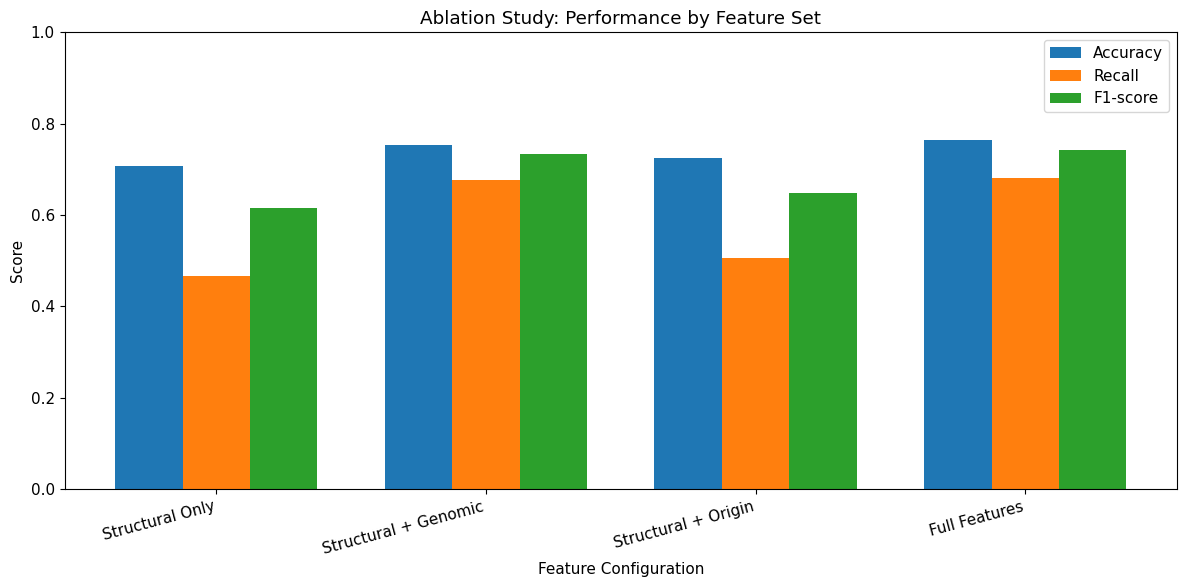

In [6]:
metrics = [
    "accuracy",
    "recall_pathogenic",
    "f1_pathogenic"
]

labels = [
    "Accuracy",
    "Recall",
    "F1-score"
]

x = np.arange(len(ablation))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for index, (metric, label) in enumerate(zip(metrics, labels)):
    ax.bar(
        x + (index - 1) * width,
        ablation[metric],
        width,
        label=label
    )

ax.set_title("Ablation Study: Performance by Feature Set")
ax.set_xlabel("Feature Configuration")
ax.set_ylabel("Score")

ax.set_xticks(x)
ax.set_xticklabels(
    ablation["Feature Set"],
    rotation=15,
    ha="right"
)

ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.show()

### 3.2 Contribution of Genomic Features

To quantify the contribution of genomic information, we compare the Structural Only and Structural + Genomic configurations.

The differences are calculated for accuracy, recall, F1-score, ROC-AUC, and PR-AUC.

Positive differences indicate improvements after adding genomic features.

The comparison is descriptive and does not establish that individual genomic features have causal effects.

In [7]:
structural = ablation.loc[
    ablation["feature_set"] == "structural_only"
].iloc[0]

genomic = ablation.loc[
    ablation["feature_set"] == "structural_plus_genomic"
].iloc[0]

metric_columns = {
    "Accuracy": "accuracy",
    "Recall": "recall_pathogenic",
    "F1-score": "f1_pathogenic",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "pr_auc"
}

contribution = pd.DataFrame({
    "Metric": list(metric_columns.keys()),
    "Structural Only": [
        structural[column]
        for column in metric_columns.values()
    ],
    "Structural + Genomic": [
        genomic[column]
        for column in metric_columns.values()
    ]
})

contribution["Improvement"] = (
    contribution["Structural + Genomic"]
    - contribution["Structural Only"]
)

contribution.round(4)

,Metric,Structural Only,Structural + Genomic,Improvement
0,Accuracy,0.7069,0.7535,0.0466
1,Recall,0.4674,0.6759,0.2085
2,F1-score,0.6146,0.7328,0.1182
3,ROC-AUC,0.7073,0.8333,0.1260
4,PR-AUC,0.6902,0.8465,0.1563


In [8]:
best_ablation = ablation.loc[
    ablation["f1_pathogenic"].idxmax()
]

print("Best Feature Configuration")
print("-" * 40)

print(f"Feature Set: {best_ablation['Feature Set']}")
print(f"Accuracy: {best_ablation['accuracy']:.4f}")
print(f"Recall: {best_ablation['recall_pathogenic']:.4f}")
print(f"F1-score: {best_ablation['f1_pathogenic']:.4f}")
print(f"ROC-AUC: {best_ablation['roc_auc']:.4f}")
print(f"PR-AUC: {best_ablation['pr_auc']:.4f}")

Best Feature Configuration
----------------------------------------
Feature Set: Full Features
Accuracy: 0.7641
Recall: 0.6803
F1-score: 0.7425
ROC-AUC: 0.8431
PR-AUC: 0.8578


### Interpretation

The ablation study demonstrates that feature selection influences model performance.

The Structural Only configuration provides useful predictive information but achieves lower overall performance than configurations incorporating genomic information.

Adding genomic features produces a substantial improvement in recall and F1-score.

The Full Features configuration achieves the highest overall F1-score, indicating that the combined feature representation is the most effective among those evaluated.

However, higher precision in some reduced configurations highlights the trade-off between identifying pathogenic variants and limiting false-positive predictions.

The results support the use of multiple complementary feature groups while emphasizing that the observed improvements are specific to the current dataset and evaluation procedure.

## 4. Gene-Based Evaluation

Random train-test splitting may place variants from the same genes in both training and testing sets.

This creates a potential limitation when evaluating generalization to genes that were not represented during training.

To investigate this issue, the project includes a gene-based evaluation using `GroupShuffleSplit`.

The splitting procedure uses gene symbols as grouping identifiers.

For each gene-based split, gene groups assigned to the test set are excluded from the training set.

The experiment is repeated five times to examine the variability of performance.

GeneSymbol is excluded from the model's predictor set in both the random-split baseline and gene-based experiments, making the feature representation more comparable.

In [9]:
# Load gene-based evaluation results.
gene_results = pd.read_csv(GENE_SPLIT_FILE)

gene_results.head()

,split,iteration,train_samples,test_samples,train_pathogenic_ratio,test_pathogenic_ratio,accuracy,precision_pathogenic,recall_pathogenic,f1_pathogenic,roc_auc,pr_auc,train_genes,test_genes
0,random_split,0,80000,20000,0.500000,0.500000,0.728400,0.856764,0.548500,0.668821,0.758375,0.794508,NaN,NaN
1,gene_based_split_1,1,77556,22444,0.493927,0.520986,0.733559,0.876499,0.568716,0.689834,0.764749,0.810180,6027.0,1507.0
2,gene_based_split_2,2,80734,19266,0.496371,0.515208,0.723503,0.865988,0.548156,0.671355,0.752733,0.798839,6027.0,1507.0
3,gene_based_split_3,3,83092,16908,0.505993,0.470546,0.728767,0.829617,0.533057,0.649066,0.725243,0.751916,6027.0,1507.0
4,gene_based_split_4,4,80278,19722,0.499290,0.502890,0.730605,0.862313,0.552531,0.673508,0.764454,0.801095,6027.0,1507.0


### 4.1 Random Split Baseline

The random-split baseline provides a reference for comparison with gene-based splitting.

Both evaluation strategies use the same general feature representation, excluding GeneSymbol.

However, they do not use identical test sets.

Consequently, differences between the two strategies should be interpreted descriptively rather than as a fully controlled comparison.

In [10]:
random_split = gene_results.loc[
    gene_results["split"] == "random_split"
].iloc[0]

baseline_metrics = [
    "accuracy",
    "precision_pathogenic",
    "recall_pathogenic",
    "f1_pathogenic",
    "roc_auc",
    "pr_auc"
]

random_baseline = pd.DataFrame({
    "Metric": baseline_metrics,
    "Random Split": [
        random_split[metric]
        for metric in baseline_metrics
    ]
})

random_baseline.round(4)

,Metric,Random Split
0,accuracy,0.7284
1,precision_pathogenic,0.8568
2,recall_pathogenic,0.5485
3,f1_pathogenic,0.6688
4,roc_auc,0.7584
5,pr_auc,0.7945


## 5. Repeated Gene-Based Splits

The gene-based experiment consists of five repeated group-based train-test splits.

Each iteration produces a different combination of training and testing genes.

The number of variants and the proportion of pathogenic examples may therefore differ between iterations.

The following analysis examines the results of each split and summarizes their variability.

In [11]:
gene_splits = gene_results[
    gene_results["split"].str.startswith(
        "gene_based_split_"
    )
].copy()

gene_splits[
    [
        "iteration",
        "train_samples",
        "test_samples",
        "accuracy",
        "precision_pathogenic",
        "recall_pathogenic",
        "f1_pathogenic",
        "roc_auc",
        "pr_auc"
    ]
].round(4)

,iteration,train_samples,test_samples,accuracy,precision_pathogenic,recall_pathogenic,f1_pathogenic,roc_auc,pr_auc
1,1,77556,22444,0.7336,0.8765,0.5687,0.6898,0.7647,0.8102
2,2,80734,19266,0.7235,0.8660,0.5482,0.6714,0.7527,0.7988
3,3,83092,16908,0.7288,0.8296,0.5331,0.6491,0.7252,0.7519
4,4,80278,19722,0.7306,0.8623,0.5525,0.6735,0.7645,0.8011
5,5,81731,18269,0.7136,0.8492,0.5150,0.6412,0.7222,0.7627


In [12]:
gene_mean = gene_splits[baseline_metrics].mean()

gene_std = gene_splits[baseline_metrics].std()

gene_summary = pd.DataFrame({
    "Metric": baseline_metrics,
    "Mean": gene_mean.values,
    "Standard Deviation": gene_std.values
})

gene_summary.round(4)

,Metric,Mean,Standard Deviation
0,accuracy,0.7260,0.0078
1,precision_pathogenic,0.8567,0.0180
2,recall_pathogenic,0.5435,0.0204
3,f1_pathogenic,0.6650,0.0197
4,roc_auc,0.7459,0.0208
5,pr_auc,0.7849,0.0259


## 6. Random vs. Gene-Based Evaluation

This section compares the random-split baseline with the average performance across five gene-based splits.

The comparison focuses on accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC.

The mean provides a summary of gene-based performance, while the standard deviation describes variability across the repeated splits.

Because the test sets differ in size and class distribution, the results should not be interpreted as a paired statistical comparison.

In [13]:
comparison = pd.DataFrame({
    "Metric": baseline_metrics,
    "Random Split": [
        random_split[metric]
        for metric in baseline_metrics
    ],
    "Gene-Based Mean": [
        gene_mean[metric]
        for metric in baseline_metrics
    ],
    "Gene-Based Std": [
        gene_std[metric]
        for metric in baseline_metrics
    ]
})

comparison["Difference (Gene - Random)"] = (
    comparison["Gene-Based Mean"]
    - comparison["Random Split"]
)

comparison.round(4)

,Metric,Random Split,Gene-Based Mean,Gene-Based Std,Difference (Gene - Random)
0,accuracy,0.7284,0.7260,0.0078,-0.0024
1,precision_pathogenic,0.8568,0.8567,0.0180,-0.0000
2,recall_pathogenic,0.5485,0.5435,0.0204,-0.0050
3,f1_pathogenic,0.6688,0.6650,0.0197,-0.0038
4,roc_auc,0.7584,0.7459,0.0208,-0.0125
5,pr_auc,0.7945,0.7849,0.0259,-0.0096


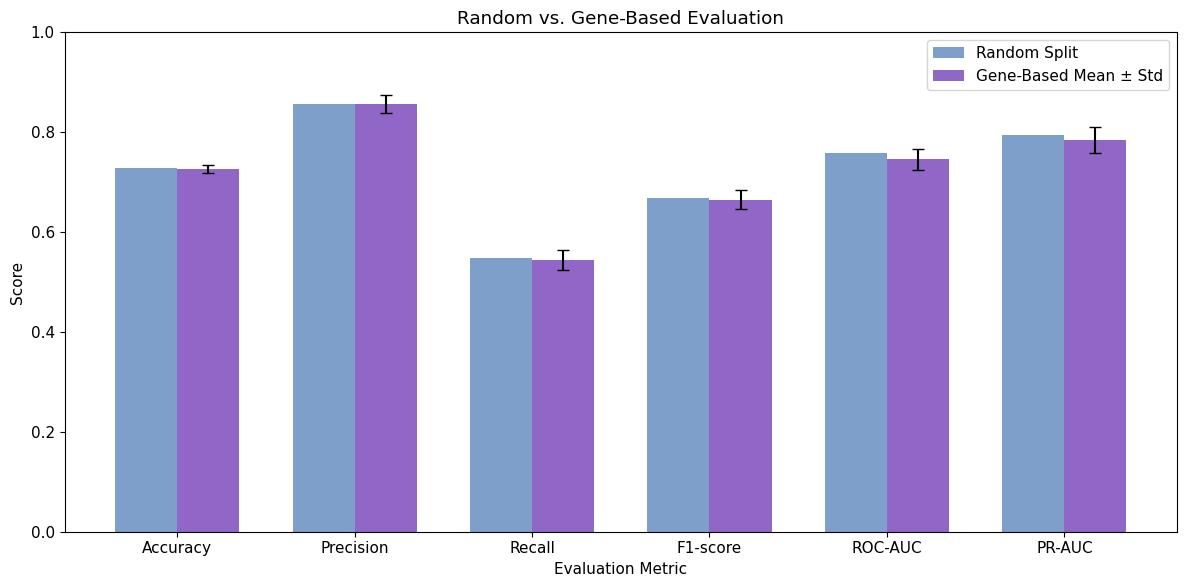

In [14]:
metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

x = np.arange(len(metric_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width / 2,
    comparison["Random Split"],
    width,
    label="Random Split",
    color=COLORS["secondary"]
)

ax.bar(
    x + width / 2,
    comparison["Gene-Based Mean"],
    width,
    yerr=comparison["Gene-Based Std"],
    capsize=4,
    label="Gene-Based Mean ± Std",
    color=COLORS["primary"]
)

ax.set_title("Random vs. Gene-Based Evaluation")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

The average gene-based performance is close to the random-split baseline across the evaluated metrics.

This suggests that the model retains a comparable level of predictive performance when evaluated on held-out gene groups in these experiments.

However, the results vary across gene-based splits.

These variations may be influenced by differences in gene composition, test-set size, and class distribution.

The findings do not establish that the model will generalize equally well to all previously unseen genes.

A more extensive evaluation would require additional datasets, independent validation, and more detailed analysis of gene-level performance.

## 7. Performance Variability Across Gene-Based Splits

Repeated group-based splitting allows us to examine how model performance changes when different gene groups are assigned to the test set.

The following visualization presents accuracy, recall, and F1-score for each of the five gene-based experiments.

This analysis helps identify whether performance is relatively stable or sensitive to the composition of the held-out genes.

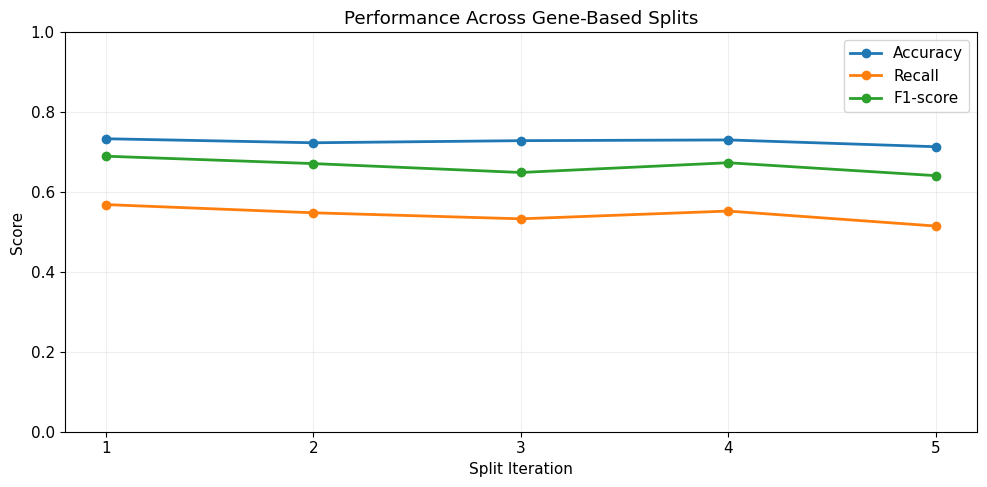

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))

metrics_to_plot = {
    "accuracy": "Accuracy",
    "recall_pathogenic": "Recall",
    "f1_pathogenic": "F1-score"
}

for metric, label in metrics_to_plot.items():
    ax.plot(
        gene_splits["iteration"],
        gene_splits[metric],
        marker="o",
        linewidth=2,
        label=label
    )

ax.set_title("Performance Across Gene-Based Splits")
ax.set_xlabel("Split Iteration")
ax.set_ylabel("Score")

ax.set_xticks(gene_splits["iteration"])
ax.set_ylim(0, 1)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Interpretation

Performance varies across the five gene-based splits.

This variability indicates that the selection of held-out gene groups can influence classification results.

Differences between iterations may reflect changes in the distribution of variants, mutation types, and target labels.

The mean and standard deviation summarize the observed variability, but five repeated splits are insufficient to characterize every possible gene-based partition.

Furthermore, repeated GroupShuffleSplit test sets may overlap, so the experiments should not be treated as independent cross-validation folds.

## 8. Class Distribution Across Gene-Based Splits

Unlike stratified random splitting, group-based splitting does not necessarily preserve the same class proportions in every test set.

As a result, the proportion of pathogenic variants may differ across gene-based iterations.

This is relevant because precision, PR-AUC, and other evaluation metrics can be affected by class prevalence.

The following analysis examines the pathogenic-class proportion in each test set.

In [16]:
class_distribution = gene_splits[
    [
        "iteration",
        "train_pathogenic_ratio",
        "test_pathogenic_ratio"
    ]
].copy()

class_distribution

,iteration,train_pathogenic_ratio,test_pathogenic_ratio
1,1,0.493927,0.520986
2,2,0.496371,0.515208
3,3,0.505993,0.470546
4,4,0.499290,0.502890
5,5,0.500704,0.496853


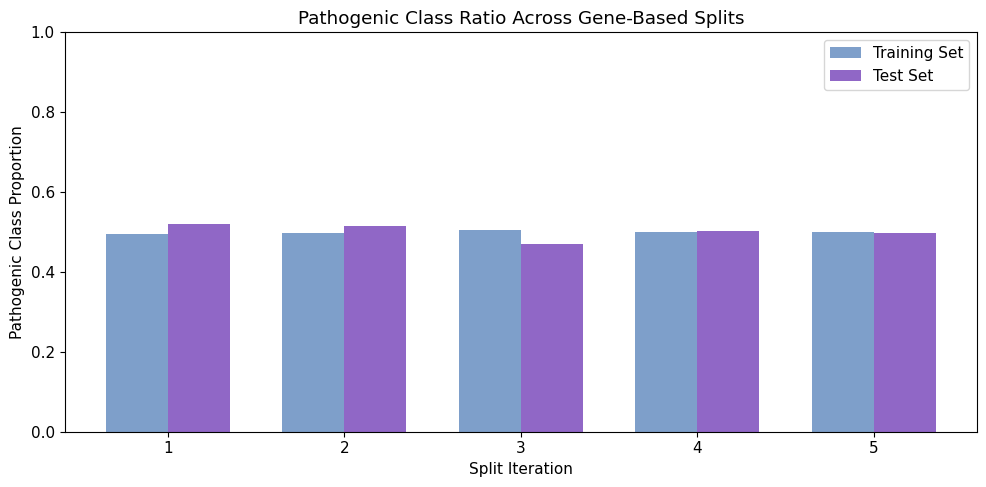

In [17]:
x = np.arange(len(class_distribution))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width / 2,
    class_distribution["train_pathogenic_ratio"],
    width,
    label="Training Set",
    color=COLORS["secondary"]
)

ax.bar(
    x + width / 2,
    class_distribution["test_pathogenic_ratio"],
    width,
    label="Test Set",
    color=COLORS["primary"]
)

ax.set_title("Pathogenic Class Ratio Across Gene-Based Splits")
ax.set_xlabel("Split Iteration")
ax.set_ylabel("Pathogenic Class Proportion")

ax.set_xticks(x)
ax.set_xticklabels(
    class_distribution["iteration"]
)

ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

The proportion of pathogenic variants differs across gene-based test sets.

These differences arise because the splitting procedure preserves gene groups rather than enforcing identical class proportions.

Consequently, some variation in performance metrics may be associated with differences in class prevalence.

This is particularly relevant when comparing precision and PR-AUC across iterations.

The results reinforce the importance of considering dataset composition when interpreting model performance.

## 9. Methodological Limitations

The experimental analyses provide useful information about model behavior, feature contributions, and generalization.

However, several limitations must be considered.

### 9.1 Limited Biological Features

The models use a restricted representation of genetic variants.

The available features include genomic identifiers, mutation types, allele lengths, and origin metadata.

They do not include functional annotations, evolutionary conservation scores, population allele frequencies, or protein-level effects.

Therefore, the models cannot capture the full biological complexity of variant pathogenicity.

### 9.2 Dataset Selection

The dataset contains 100,000 variants sampled from ClinVar.

The classes were balanced intentionally, so the observed distribution does not represent the natural prevalence of pathogenic variants.

The models may also reflect submission patterns and annotation practices present in ClinVar.

### 9.3 Feature Importance Limitations

Logistic Regression coefficients and Random Forest impurity-based importance values describe model behavior.

They do not establish causal biological relationships.

Their interpretation can be affected by feature encoding, correlations, and differences in feature cardinality.

### 9.4 Gene-Based Evaluation

The gene-based evaluation uses five repeated GroupShuffleSplit experiments.

Although the procedure separates gene groups between training and testing within each split, repeated test sets may overlap.

The experiment does not provide an independent external validation dataset.

### 9.5 Clinical Applicability

The models are research prototypes developed for computational experimentation.

Their predictions have not been clinically validated.

They must not be used for diagnosis, treatment decisions, or clinical interpretation of individual genetic variants.

## 10. Final Summary and Conclusions

This notebook investigated three complementary aspects of the genetic variant classification project:

1. Model interpretability.
2. Feature-group contributions.
3. Generalization to held-out gene groups.

### Feature Importance

Logistic Regression coefficients and Random Forest feature importance provide different perspectives on how the models use genomic and structural characteristics.

These methods support model interpretation but do not establish biological causality.

### Ablation Study

The ablation experiments demonstrate that the selected feature groups contribute differently to classification performance.

Adding genomic information improves performance compared with structural features alone.

The Full Features configuration achieves the highest F1-score among the evaluated alternatives.

### Gene-Based Evaluation

The repeated gene-based experiments produce average performance values close to the random-split baseline.

However, performance varies across the five splits, and the test sets differ in composition and class prevalence.

The results provide preliminary evidence about performance on held-out gene groups, but they do not establish generalization to all unseen genes.

### Overall Conclusion

The experiments show that relatively simple machine learning models can identify statistical patterns associated with ClinVar pathogenicity labels using a limited feature representation.

Logistic Regression provides the strongest overall performance in the main model comparison.

The additional experiments highlight the importance of feature selection, evaluation design, and careful interpretation of predictive performance.

The project should be regarded as a machine learning research prototype rather than a clinically validated variant interpretation system.